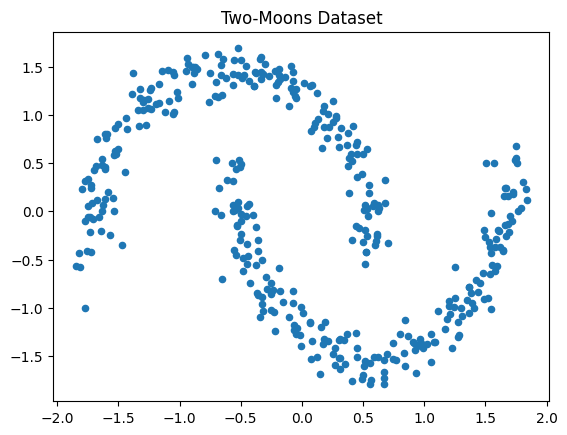

,eps,min_samples,clusters,noise_points
0,0.15,5,8,21
1,0.20,5,3,3
2,0.25,5,2,1
3,0.30,5,2,1
4,0.25,10,2,6


Clusters found: 2
Noise points: 1
Labels: [-1  0  1]


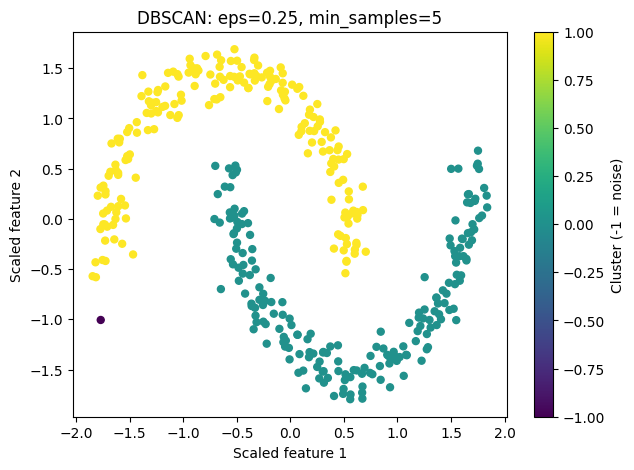

Silhouette (excluding noise): 0.37922877943331573


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

X, _ = make_moons(n_samples=400, noise=0.07, random_state=42)
X_scaled = StandardScaler().fit_transform(X)
plt.scatter(X_scaled[:,0], X_scaled[:,1], s=20)
plt.title("Two-Moons Dataset")
plt.show()

settings = [(0.15,5), (0.20,5), (0.25,5), (0.30,5), (0.25,10)]
rows = []
for eps, min_samples in settings:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
    rows.append({"eps":eps, "min_samples":min_samples,
                 "clusters":len(set(labels)-{-1}),
                 "noise_points":int(np.sum(labels == -1))})
display(pd.DataFrame(rows))

eps_value, min_samples_value = 0.25, 5
db = DBSCAN(eps=eps_value, min_samples=min_samples_value)
labels = db.fit_predict(X_scaled)
print("Clusters found:", len(set(labels)-{-1}))
print("Noise points:", int(np.sum(labels == -1)))
print("Labels:", np.unique(labels))

plt.figure(figsize=(7,5))
scatter = plt.scatter(X_scaled[:,0], X_scaled[:,1], c=labels, cmap="viridis", s=25)
plt.title(f"DBSCAN: eps={eps_value}, min_samples={min_samples_value}")
plt.xlabel("Scaled feature 1")
plt.ylabel("Scaled feature 2")
plt.colorbar(scatter, label="Cluster (-1 = noise)")
plt.show()

mask = labels != -1
if len(set(labels[mask])) >= 2:
    print("Silhouette (excluding noise):", silhouette_score(X_scaled[mask], labels[mask]))
else:
    print("Silhouette not calculated: fewer than two non-noise clusters.")